## Download Data

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip -q install gdown

!mkdir "/content/DataStorage"
!mkdir "/content/DataStorage/EEG_Classification"



In [3]:
!gdown --fuzzy \
  "https://drive.google.com/file/d/1vupFWT0OZHk_TLWeC_D5U1f3cKsqp5Xf/view?usp=sharing" \
  -O "/content/DataStorage/EEG_Classification/sub-03__63_channels.zip"

Downloading...
From (original): https://drive.google.com/uc?id=1vupFWT0OZHk_TLWeC_D5U1f3cKsqp5Xf
From (redirected): https://drive.google.com/uc?id=1vupFWT0OZHk_TLWeC_D5U1f3cKsqp5Xf&confirm=t&uuid=64a2f41a-915f-4fc9-8574-b8c8ac6b5fd0
To: /content/DataStorage/EEG_Classification/sub-03__63_channels.zip
100% 4.03G/4.03G [00:35<00:00, 113MB/s]


In [4]:
!unzip -o "/content/DataStorage/EEG_Classification/sub-03__63_channels.zip" -d "/content/DataStorage/EEG_Classification/"

Archive:  /content/DataStorage/EEG_Classification/sub-03__63_channels.zip
   creating: /content/DataStorage/EEG_Classification/sub-03__63_channels/
  inflating: /content/DataStorage/EEG_Classification/sub-03__63_channels/preprocessed_eeg_test.npy  
  inflating: /content/DataStorage/EEG_Classification/sub-03__63_channels/preprocessed_eeg_training.npy  


In [5]:
!gdown --fuzzy \
  "https://drive.google.com/file/d/1ZM7FLolMjDGzz_gXE92jQZjDhc2pdP0W/view?usp=drive_link" \
  -O "/content/DataStorage/EEG_Classification/clip_embeddings_train.npy"

Downloading...
From: https://drive.google.com/uc?id=1ZM7FLolMjDGzz_gXE92jQZjDhc2pdP0W
To: /content/DataStorage/EEG_Classification/clip_embeddings_train.npy
100% 33.9M/33.9M [00:00<00:00, 46.8MB/s]


In [6]:
!gdown --fuzzy \
  "https://drive.google.com/file/d/1cRuncV-FRI4JQHKD-rMg-CtZaZgT2TjO/view?usp=sharing" \
  -O "/content/DataStorage/EEG_Classification/clip_embeddings_test.npy"

Downloading...
From: https://drive.google.com/uc?id=1cRuncV-FRI4JQHKD-rMg-CtZaZgT2TjO
To: /content/DataStorage/EEG_Classification/clip_embeddings_test.npy
100% 410k/410k [00:00<00:00, 6.45MB/s]


In [7]:
!gdown --fuzzy \
  "https://drive.google.com/file/d/12UH2WjWaOuW4zejYnATrGmO0_9jl92w2/view?usp=drive_link" \
  -O "/content/DataStorage/EEG_Classification/eeg_image_mapping.csv"

Downloading...
From: https://drive.google.com/uc?id=12UH2WjWaOuW4zejYnATrGmO0_9jl92w2
To: /content/DataStorage/EEG_Classification/eeg_image_mapping.csv
100% 2.24M/2.24M [00:00<00:00, 19.3MB/s]


## Import library

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
random_state = 59
np.random.seed(random_state)
torch.manual_seed(random_state)
if torch.cuda.is_available():
    torch.cuda.manual_seed(random_state)

Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime


## Processing data

In [9]:
data_train_path = "/content/DataStorage/EEG_Classification/sub-03__63_channels/preprocessed_eeg_training.npy"
data_test_path = "/content/DataStorage/EEG_Classification/sub-03__63_channels/preprocessed_eeg_test.npy"


data_EEG_train = np.load(data_train_path, allow_pickle=True)
data_EEG_test = np.load(data_test_path, allow_pickle=True)



In [10]:
data_train_EEG_arr = data_EEG_train.item()['preprocessed_eeg_data']     # (16540, 4, 64, 100)
data_test_EEG_arr = data_EEG_test.item()["preprocessed_eeg_data"]       # (200, 80, 64, 100)

data_train_EEG_tensor = torch.from_numpy(data_train_EEG_arr).to(torch.float32)  # Size([16540, 4, 64, 100])
data_test_EEG_tensor = torch.from_numpy(data_test_EEG_arr).to(torch.float32)    # Size([200, 80, 64, 100])

# Get 63 channels

data_train_EEG_63_tensor = data_train_EEG_tensor[:,:,:63,:]   # 16540, 4, 63, 100
data_test_EEG_63_tensor = data_test_EEG_tensor[:,:,:63,:]     # 200, 80, 63, 100


In [11]:
# Data 63 channel EEG average session

data_train_EEG_63_tensor_avg = torch.mean(data_train_EEG_63_tensor, dim=1)    # 16540, 63, 100
data_test_EEG_63_tensor_avg = torch.mean(data_test_EEG_63_tensor, dim=1)      # 200, 63, 100

In [12]:
# Data CLIP embedding

data_CLIP_train_path = "/content/DataStorage/EEG_Classification/clip_embeddings_train.npy"
data_CLIP_test_path = "/content/DataStorage/EEG_Classification/clip_embeddings_test.npy"

data_CLIP_train = np.load(data_CLIP_train_path, allow_pickle=True)
data_CLIP_test = np.load(data_CLIP_test_path, allow_pickle=True)


data_CLIP_train_tensor = torch.from_numpy(data_CLIP_train)  # Size([16540, 512])
data_CLIP_test_tensor = torch.from_numpy(data_CLIP_test)    # Size([200, 512])


In [13]:
print(data_train_EEG_63_tensor.shape)
print(data_test_EEG_63_tensor.shape)

print(data_train_EEG_63_tensor_avg.shape)
print(data_test_EEG_63_tensor_avg.shape)

print(data_CLIP_train_tensor.shape)
print(data_CLIP_test_tensor.shape)

torch.Size([16540, 4, 63, 100])
torch.Size([200, 80, 63, 100])
torch.Size([16540, 63, 100])
torch.Size([200, 63, 100])
torch.Size([16540, 512])
torch.Size([200, 512])


In [14]:
# Get label for test data

import pandas as pd

# Converting the sharing link into a direct download link
file_id = "1NaE-lKVGFBFR7v5slUflu7tVpKAXlecL"
test_label_path = f"https://docs.google.com/uc?export=download&id={file_id}"

test_label = pd.read_csv(test_label_path)
label_test = test_label["concept"].tolist()

print(len(label_test))  # Expected: 200
print(label_test[:5])


200
['aircraft_carrier', 'antelope', 'backscratcher', 'balance_beam', 'banana']


## For AVERAGE experiment: Split data and Normalization data

In [15]:
# Split data

import torch

# EEG input: [N, 64, 100]
# CLIP target: [N, 512]

N = len(data_train_EEG_63_tensor_avg)
#split_idx = int(N * 0.8)
split_idx = 13230

# Train: ~80% first
X_train_avg = data_train_EEG_63_tensor_avg[:split_idx]    # Size([13230, 63, 100])
Y_train_avg = data_CLIP_train_tensor[:split_idx]          # Size([13230, 512])

# Validation: ~20% last
X_val_avg = data_train_EEG_63_tensor_avg[split_idx:]      # Size([3310, 63, 100])
Y_val_avg = data_CLIP_train_tensor[split_idx:]            # Size([3310, 512])

# Test: 200 sample
X_test_avg = data_test_EEG_63_tensor_avg       # Size([200, 63, 100])
Y_test_avg = data_CLIP_test_tensor             # Size([200, 512])


In [16]:
print("X_train_avg:", X_train_avg.shape, "| Y_train_avg:", Y_train_avg.shape)
print("X_val_avg:  ", X_val_avg.shape,   "| Y_val_avg:  ", Y_val_avg.shape)
print("X_test: ", X_test_avg.shape,  "| Y_test: ", Y_test_avg.shape)

X_train_avg: torch.Size([13230, 63, 100]) | Y_train_avg: torch.Size([13230, 512])
X_val_avg:   torch.Size([3310, 63, 100]) | Y_val_avg:   torch.Size([3310, 512])
X_test:  torch.Size([200, 63, 100]) | Y_test:  torch.Size([200, 512])


In [17]:
# Normalize data

mean_avg = X_train_avg.mean(axis=(0, 2), keepdims=True)
std_avg  = X_train_avg.std(axis=(0, 2), keepdims=True)

X_train_norm_avg = (X_train_avg - mean_avg) / (std_avg + 1e-8)
X_val_norm_avg   = (X_val_avg   - mean_avg) / (std_avg + 1e-8)
X_test_norm_avg  = (X_test_avg  - mean_avg) / (std_avg + 1e-8)


In [18]:
print("X_train_norm_avg:", X_train_norm_avg.shape, "| Y_train_avg:", Y_train_avg.shape)
print("X_val_norm_avg:  ", X_val_avg.shape,   "| Y_val_avg:  ", Y_val_avg.shape)
print("X_test_norm_avg: ", X_test_avg.shape,  "| Y_test: ", Y_test_avg.shape)

X_train_norm_avg: torch.Size([13230, 63, 100]) | Y_train_avg: torch.Size([13230, 512])
X_val_norm_avg:   torch.Size([3310, 63, 100]) | Y_val_avg:   torch.Size([3310, 512])
X_test_norm_avg:  torch.Size([200, 63, 100]) | Y_test:  torch.Size([200, 512])


In [19]:
import pandas as pd
import numpy as np

csv_path = "/content/DataStorage/EEG_Classification/eeg_image_mapping.csv"

df = pd.read_csv(csv_path)

# Create integer concept IDs
df["concept_id"], unique_concepts = pd.factorize(df["concept"])

concept_ids = df["concept_id"].to_numpy()

print("Number of images:", len(df))
print("Number of concepts:", len(unique_concepts))
#print(df[["eeg_idx", "concept", "concept_id"]].head(15))

val_idx = np.arange(split_idx, len(data_train_EEG_63_tensor_avg))

train_idx = np.arange(0, split_idx)

concept_ids_val = torch.tensor(
    df.iloc[val_idx]["concept_id"].to_numpy(),
    dtype=torch.long
)   # 3310

concept_ids_train = torch.tensor(
    df.iloc[train_idx]["concept_id"].to_numpy(),
    dtype=torch.long
)   # 13230


Number of images: 16540
Number of concepts: 1654


In [20]:
print(concept_ids_val.shape)
print(val_idx)
print(train_idx)

torch.Size([3310])
[13230 13231 13232 ... 16537 16538 16539]
[    0     1     2 ... 13227 13228 13229]


## For AVERAGE experiment: Data Loader

In [21]:
import torch
from torch.utils.data import Sampler
from collections import defaultdict

class CustomDataset(Dataset):
    def __init__(self, X, y, concept_ids=None):
        self.X = X
        self.y = y
        self.concept_ids = concept_ids
        pass

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        if self.concept_ids is None:
            return self.X[idx], self.y[idx]
        return self.X[idx], self.y[idx], self.concept_ids[idx]

class EEGDataset(Dataset):
    def __init__(self, X, y, concept_ids):
        self.X = X
        self.y = y
        self.concept_ids = concept_ids

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return (
            self.X[idx],
            self.y[idx],
            self.concept_ids[idx]
        )

class UniqueConceptBatchSampler(Sampler):
    def __init__(
        self,
        concept_ids,
        batch_size=32,
        drop_last=True
    ):
        self.batch_size = batch_size
        self.drop_last = drop_last

        self.concept_to_indices = defaultdict(list)

        for idx, concept in enumerate(concept_ids.tolist()):
            self.concept_to_indices[int(concept)].append(idx)

        self.concepts = list(self.concept_to_indices.keys())

    def __iter__(self):
        # Shuffle concepts
        concept_order = torch.randperm(len(self.concepts)).tolist()

        selected_indices = []

        for i in concept_order:
            concept = self.concepts[i]
            candidates = self.concept_to_indices[concept]

            # Randomly select one image/session sample
            random_pos = torch.randint(len(candidates), (1,)).item()
            selected_indices.append(candidates[random_pos])

        # Create batches
        for i in range(0, len(selected_indices), self.batch_size):
            batch = selected_indices[i:i + self.batch_size]

            if len(batch) == self.batch_size or not self.drop_last:
                yield batch

    def __len__(self):
        if self.drop_last:
            return len(self.concepts) // self.batch_size
        return (len(self.concepts) + self.batch_size - 1) // self.batch_size


In [22]:
train_dataset_avg = CustomDataset(X_train_norm_avg, Y_train_avg, concept_ids_train)
val_dataset_avg = CustomDataset(X_val_norm_avg, Y_val_avg, concept_ids_val)
#test_dataset = CustomDataset(X_test, Y_test)

train_loader_avg = DataLoader(train_dataset_avg, batch_size=32, shuffle=True)
val_loader_avg = DataLoader(val_dataset_avg, batch_size=32, shuffle=False)
#test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)



In [ ]:
test_dataset_avg = EEGDataset(
    X_test_norm_avg.float(),
    Y_test_avg, # 200 target embeddings
    torch.arange(200) # 200 concept IDs
)

test_loader_avg = DataLoader(
    test_dataset_avg,
    batch_size=200,
    shuffle=False
)

## Loss function and Metric

In [ ]:
# contrastive_loss

import torch
import torch.nn.functional as F

def contrastive_loss(eeg_embeddings, image_embeddings, temperature=0.07):
    # L2 normalize embeddings
    eeg_embeddings = F.normalize(eeg_embeddings.float(), dim=1)
    image_embeddings = F.normalize(image_embeddings.float(), dim=1)

    # Similarity matrix: (batch_size, batch_size)
    logits = eeg_embeddings @ image_embeddings.T

    # Temperature scaling
    logits = logits / temperature

    # Positive pairs on the main diagonal
    batch_size = eeg_embeddings.shape[0]
    labels = torch.arange(batch_size, device=eeg_embeddings.device)

    # EEG -> Image
    loss_eeg_to_image = F.cross_entropy(logits, labels)

    # Image -> EEG
    loss_image_to_eeg = F.cross_entropy(logits.T, labels)

    # Symmetric InfoNCE
    loss = (loss_eeg_to_image + loss_image_to_eeg) / 2

    return loss

In [ ]:
# Metric for training


import torch
import torch.nn.functional as F

def recall_at_k(model, loader, device, k=5):
    model.eval()

    all_preds = []
    all_targets = []

    with torch.no_grad():
        for data, target, _ in loader:
            data = data.to(device)

            output = model(data)

            all_preds.append(output.cpu())
            all_targets.append(target.cpu())

    # [N, 512]
    all_preds = torch.cat(all_preds, dim=0)
    all_targets = torch.cat(all_targets, dim=0)

    # normalize data for cosine similarity
    all_preds = F.normalize(all_preds, p=2, dim=1)
    all_targets = F.normalize(all_targets, p=2, dim=1)

    # [N_query, N_candidates]
    similarity = all_preds @ all_targets.T

    # Top-k candidate / query
    k = min(k, all_targets.size(0))
    topk_indices = similarity.topk(k, dim=1).indices

    correct_indices = torch.arange(all_preds.size(0)).unsqueeze(1)

    hits = (topk_indices == correct_indices).any(dim=1)

    recall = hits.float().mean().item()

    return recall


In [ ]:
# Metric for validation

import torch
import torch.nn.functional as F
import numpy as np

@torch.no_grad()
def recall_at_k_test_matched(
    model,
    loader,
    device,
    ks=(1, 5, 10),
    n_trials=200,
    seed=42
):
    model.eval()

    all_preds = []
    all_targets = []
    all_concept_ids = []

    #Predict all validation data
    for data, target, concept_id in loader:

        data = data.to(device)

        output = model(data)

        all_preds.append(output.cpu())
        all_targets.append(target.cpu())

        all_concept_ids.append(concept_id.cpu())

    all_preds = torch.cat(all_preds, dim=0)
    all_targets = torch.cat(all_targets, dim=0)
    all_concept_ids = torch.cat(all_concept_ids, dim=0).numpy()

    
    all_preds = F.normalize(all_preds, p=2, dim=1)
    all_targets = F.normalize(all_targets, p=2, dim=1)


    unique_concepts = np.unique(all_concept_ids)
    n_concepts = len(unique_concepts)

    
    concept_indices = {
        concept: np.where(all_concept_ids == concept)[0]
        for concept in unique_concepts
    }

    rng = np.random.default_rng(seed)

    results = {k: [] for k in ks}

    
    for trial in range(n_trials):

        selected_indices = []

        for concept in unique_concepts:

            candidates = concept_indices[concept]

            selected_idx = rng.choice(candidates)

            selected_indices.append(selected_idx)

        selected_indices = np.array(selected_indices)

        # EEG queries
        query = all_preds[selected_indices]

        # CLIP gallery
        gallery = all_targets[selected_indices]

        similarity = query @ gallery.T

        correct_similarity = similarity.diag().unsqueeze(1)

        ranks = (similarity > correct_similarity).sum(dim=1)

        for k in ks:

            k_actual = min(k, n_concepts)

            recall = (ranks < k_actual).float().mean().item()

            results[k].append(recall)

    summary = {}

    for k in ks:

        values = np.array(results[k])

        summary[f"Recall@{k}"] = {
            "mean": values.mean(),
            "std": values.std(),
            "chance": min(k, n_concepts) / n_concepts
        }

    return summary

In [ ]:
# Metric for AVG testing

import torch
import torch.nn.functional as F
import numpy as np

def calculate_recall_at_k(
    eeg_embeddings,
    image_embeddings,
    eeg_concept_ids,
    image_concept_ids,
    ks=(1, 5, 10)
):
    """
    EEG-to-image retrieval.

    eeg_embeddings:      (N, 512)
    image_embeddings:    (M, 512)
    eeg_concept_ids:     (N,)
    image_concept_ids:   (M,)
    """

    eeg_embeddings = F.normalize(
        eeg_embeddings, p=2, dim=1
    )

    image_embeddings = F.normalize(
        image_embeddings, p=2, dim=1
    )

    # Similarity matrix: (N, M)
    similarity = eeg_embeddings @ image_embeddings.T

    # Map each EEG concept to its corresponding image index
    image_id_to_index = {
        int(concept_id): idx
        for idx, concept_id in enumerate(image_concept_ids)
    }

    assert len(image_id_to_index) == len(image_concept_ids), \
        "Duplicate image concept IDs detected."

    gt_indices = torch.tensor(
        [
            image_id_to_index[int(concept_id)]
            for concept_id in eeg_concept_ids
        ],
        device=similarity.device
    )

    # Ground-truth rank using top-k ordering
    sorted_indices = torch.argsort(
        similarity,
        dim=1,
        descending=True
    )

    # Find rank of ground-truth image
    ranks = (
        sorted_indices == gt_indices.unsqueeze(1)
    ).nonzero(as_tuple=False)[:, 1] + 1

    # Calculate Recall@K
    results = {}

    n_candidates = image_embeddings.shape[0]

    for k in ks:
        k_actual = min(k, n_candidates)

        recall = (
            (ranks <= k_actual).float().mean().item()
        )

        results[f"Recall@{k}"] = recall

    return results

### Initialization weight

In [ ]:
import torch
import torch.nn as nn

def init_weights_he(m):
    if isinstance(m, (nn.Conv1d, nn.Linear)):
        # He initialization for layer has ReLU activation
        nn.init.kaiming_normal_(
            m.weight,
            mode='fan_in',
            nonlinearity='relu'
        )

        if m.bias is not None:
            nn.init.zeros_(m.bias)

    elif isinstance(m, (nn.BatchNorm1d, nn.LayerNorm)):
        if m.weight is not None:
            nn.init.ones_(m.weight)

        if m.bias is not None:
            nn.init.zeros_(m.bias)

## Model: MLP

In [29]:
class MLP(nn.Module):
    # Setup MLP layer
    def __init__(self, input_dims, hidden1_dims, hidden2_dims, output_dims):
        super(MLP,self).__init__()
        self.flatten = nn.Flatten()
        self.linear1 = nn.Linear(input_dims, hidden1_dims)
        self.layerNorm = nn.LayerNorm(hidden1_dims)
        #self.linear2 = nn.Linear(hidden1_dims, hidden2_dims)
        #self.output = nn.Linear(hidden2_dims, output_dims)
        self.output = nn.Linear(hidden1_dims, output_dims)

    # input --> Flatten --> linear1 --> ReLU --> linear2 --> ReLU --> Dropout(0.4) --> output
    # def forward(self, x):
    #     x = self.flatten(x)
    #     x = self.linear1(x)
    #     x = self.layerNorm(x)
    #     x = F.relu(x)
    #     x = self.linear2(x)
    #     x = F.relu(x)
    #     x = F.dropout(x, p=0.4)
    #     output = self.output(x)
    #     return output

    def forward(self, x):
        x = self.flatten(x)
        x = self.linear1(x)
        x = self.layerNorm(x)
        x = F.relu(x)
        # x = self.linear2(x)
        # x = F.relu(x)
        x = F.dropout(x, p=0.4)
        output = self.output(x)
        return output

In [ ]:
print(X_train_norm_avg.shape)

torch.Size([13230, 63, 100])


In [ ]:
input_dims = X_train_avg.shape[1] * X_train_avg.shape[2]    # 63*100

hidden1_dims = 1024
hidden2_dims = 512
output_dims = 512

model = MLP(input_dims=input_dims, hidden1_dims=hidden1_dims, hidden2_dims=hidden2_dims,  output_dims=output_dims).to(device)


criterion = contrastive_loss
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3
)

## Model: Conv1D

In [ ]:
class ImprovedConv1d_v2(nn.Module):
    def __init__(self, input_channels, output_dims):
        super(ImprovedConv1d_v2, self).__init__()
        # input: [Batch, 64, 100]
        self.conv_block1 = nn.Sequential(
            nn.Conv1d(in_channels=input_channels, out_channels=128, kernel_size=5, stride=1, padding=2),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.AvgPool1d(kernel_size=2) # -> [Batch, 128, 50]
        )

        self.conv_block2 = nn.Sequential(
            nn.Conv1d(in_channels=128, out_channels=256, kernel_size=5, stride=1, padding=2),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.AvgPool1d(kernel_size=2) # -> [Batch, 256, 25]
        )

        self.conv_block3 = nn.Sequential(
            nn.Conv1d(in_channels=256, out_channels=512, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(8)
        )

        # Flatten: 512 * 8 = 4096
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512 * 8, 1024),
            nn.LayerNorm(1024),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(1024, output_dims)
        )

    def forward(self, x):
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = self.fc(x)
        return x

In [ ]:
model = ImprovedConv1d_v2(input_channels=63, output_dims=512).to(device)

model.apply(init_weights_he)

criterion = contrastive_loss

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)


## For AVERAGE experiment: Training and validation

In [ ]:
#!mkdir "/content/DataStorage/EEG_Classification/checkpoints"
!mkdir "/content/DataStorage/EEG_Classification/checkpoints/Experiment_AVG"

mkdir: cannot create directory ‘/content/DataStorage/EEG_Classification/checkpoints/Experiment_AVG’: File exists


In [ ]:
import torch
import os

# =====================================
# CONFIGURATION
# =====================================

epochs = 15


save_dir = '/content/DataStorage/EEG_Classification/checkpints/Experiment_AVG/'
os.makedirs(save_dir, exist_ok=True)

best_model_path = os.path.join(save_dir, 'best_model_MLP_ex2.pth')

train_losses = []
val_losses = []

train_recalls_at_5 = []
val_recalls_at_5 = []
val_recalls_at_5_std = []

# Best model based on Validation Test-matched Recall@5
best_val_r5 = -float('inf')
best_epoch = 0

# =====================================
# TRAINING LOOP
# =====================================

for epoch in range(epochs):

    train_loss = 0.0
    val_loss = 0.0

    train_target = []
    val_target = []
    train_predict = []
    val_predict = []

    # =====================================
    # 1. TRAINING
    # =====================================

    model.train()

    for X_samples, y_samples, _ in train_loader_avg:

        X_samples = X_samples.to(device)
        y_samples = y_samples.to(device)

        optimizer.zero_grad()

        outputs = model(X_samples)

        train_predict += outputs.tolist()
        train_target += y_samples.tolist()

        loss = criterion(outputs, y_samples)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader_avg)
    train_losses.append(train_loss)

    # =====================================
    # 2. TRAIN RECALL@5
    # =====================================

    train_r5 = recall_at_k(
        model,
        train_loader_avg,
        device,
        k=5
    )

    train_recalls_at_5.append(train_r5)

    # =====================================
    # 3. VALIDATION LOSS
    # =====================================

    model.eval()

    with torch.no_grad():

        for X_samples, y_samples, concept_id in val_loader_avg:

            X_samples = X_samples.to(device)
            y_samples = y_samples.to(device)

            outputs = model(X_samples)

            val_predict += outputs.tolist()
            val_target += y_samples.tolist()

            loss = criterion(outputs, y_samples)

            val_loss += loss.item()

    val_loss /= len(val_loader_avg)
    val_losses.append(val_loss)

    # =====================================
    # 4. TEST-MATCHED VALIDATION RECALL
    # =====================================

    val_result = recall_at_k_test_matched(
        model=model,
        loader=val_loader_avg,
        device=device,
        ks=(5,),
        n_trials=200,
        seed=42
    )

    val_r5 = val_result["Recall@5"]["mean"]
    val_r5_std = val_result["Recall@5"]["std"]

    val_recalls_at_5.append(val_r5)
    val_recalls_at_5_std.append(val_r5_std)

    # =====================================
    # 5. SAVE BEST MODEL
    # =====================================

    if val_r5 > best_val_r5:

        best_val_r5 = val_r5
        best_epoch = epoch + 1

        torch.save({
            'epoch': best_epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),

            'best_val_r5': best_val_r5,
            'val_r5_std': val_r5_std,
            'val_loss': val_loss,

        }, best_model_path)

        print(f'--> Best model saved at epoch {best_epoch}')

    # =====================================
    # 6. PRINT RESULTS
    # =====================================

    print(
        f'\nEPOCH {epoch + 1}:'
        f'\tTraining loss: {train_loss:.3f}'
        f'\tValidation loss: {val_loss:.3f}'
        f'\tTrain Recall@5: {train_r5:.4f}'
        f'\tVal Test-matched Recall@5: '
        f'{val_r5:.4f} +/- {val_r5_std:.4f}'
        f'\tBest Val Recall@5: {best_val_r5:.4f}'
    )

print('\n=====================================')
print('TRAINING COMPLETED')
print(f'Best epoch: {best_epoch}')
print(f'Best Validation Recall@5: {best_val_r5:.4f}')
print(f'Model saved at: {best_model_path}')
print('=====================================')

--> Best model saved at epoch 1

EPOCH 1:	Training loss: 3.005	Validation loss: 3.023	Train Recall@5: 0.0426	Val Test-matched Recall@5: 0.1230 +/- 0.0170	Best Val Recall@5: 0.1230
--> Best model saved at epoch 2

EPOCH 2:	Training loss: 2.266	Validation loss: 2.955	Train Recall@5: 0.1190	Val Test-matched Recall@5: 0.1553 +/- 0.0177	Best Val Recall@5: 0.1553
--> Best model saved at epoch 3

EPOCH 3:	Training loss: 1.826	Validation loss: 2.961	Train Recall@5: 0.2657	Val Test-matched Recall@5: 0.1615 +/- 0.0160	Best Val Recall@5: 0.1615

EPOCH 4:	Training loss: 1.469	Validation loss: 2.997	Train Recall@5: 0.4261	Val Test-matched Recall@5: 0.1573 +/- 0.0167	Best Val Recall@5: 0.1615

EPOCH 5:	Training loss: 1.176	Validation loss: 3.030	Train Recall@5: 0.5818	Val Test-matched Recall@5: 0.1576 +/- 0.0182	Best Val Recall@5: 0.1615

EPOCH 6:	Training loss: 0.937	Validation loss: 3.055	Train Recall@5: 0.7253	Val Test-matched Recall@5: 0.1429 +/- 0.0184	Best Val Recall@5: 0.1615

EPOCH 7:	Traini

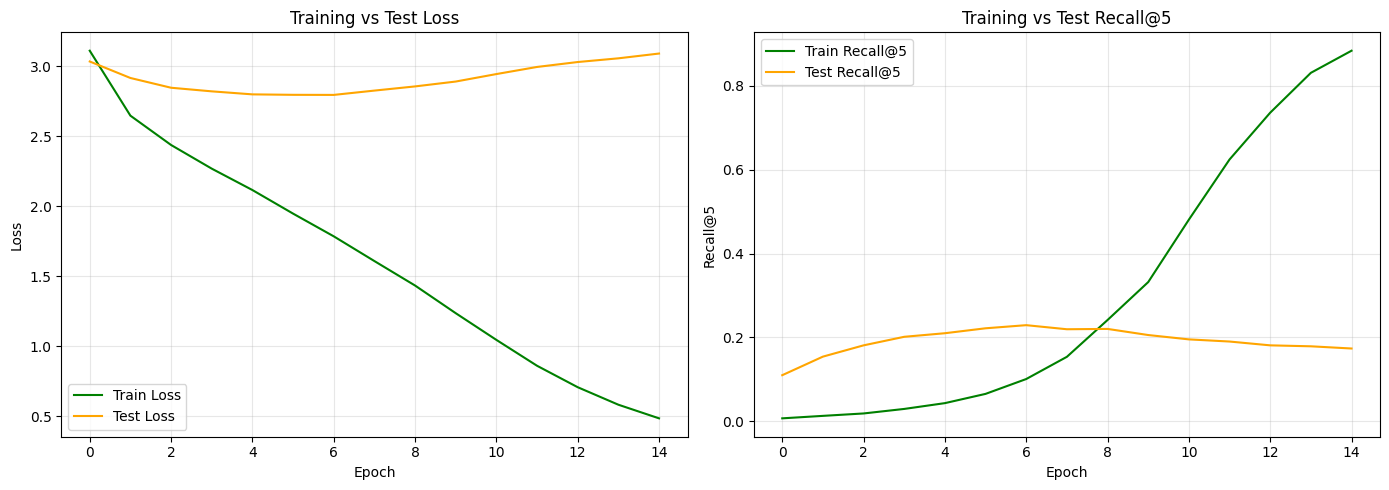

In [ ]:
# Plot for average session

# Convert GPU tensors to CPU float values for plotting
train_recall_plot = [
    r.cpu().item() if isinstance(r, torch.Tensor) else r
    for r in train_recalls_at_5
]

val_recall_plot = [
    r.cpu().item() if isinstance(r, torch.Tensor) else r
    for r in val_recalls_at_5
]

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# ==========================================
# 1. Loss: Training vs Test
# ==========================================
ax[0].plot(train_losses, label='Train Loss', color='green')
ax[0].plot(val_losses, label='Test Loss', color='orange')

ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Loss')
ax[0].set_title('Training vs Test Loss')
ax[0].legend()
ax[0].grid(True, alpha=0.3)

# ==========================================
# 2. Recall@5: Training vs Test
# ==========================================
ax[1].plot(train_recall_plot, label='Train Recall@5', color='green')
ax[1].plot(val_recall_plot, label='Test Recall@5', color='orange')

ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Recall@5')
ax[1].set_title('Training vs Test Recall@5')
ax[1].legend()
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

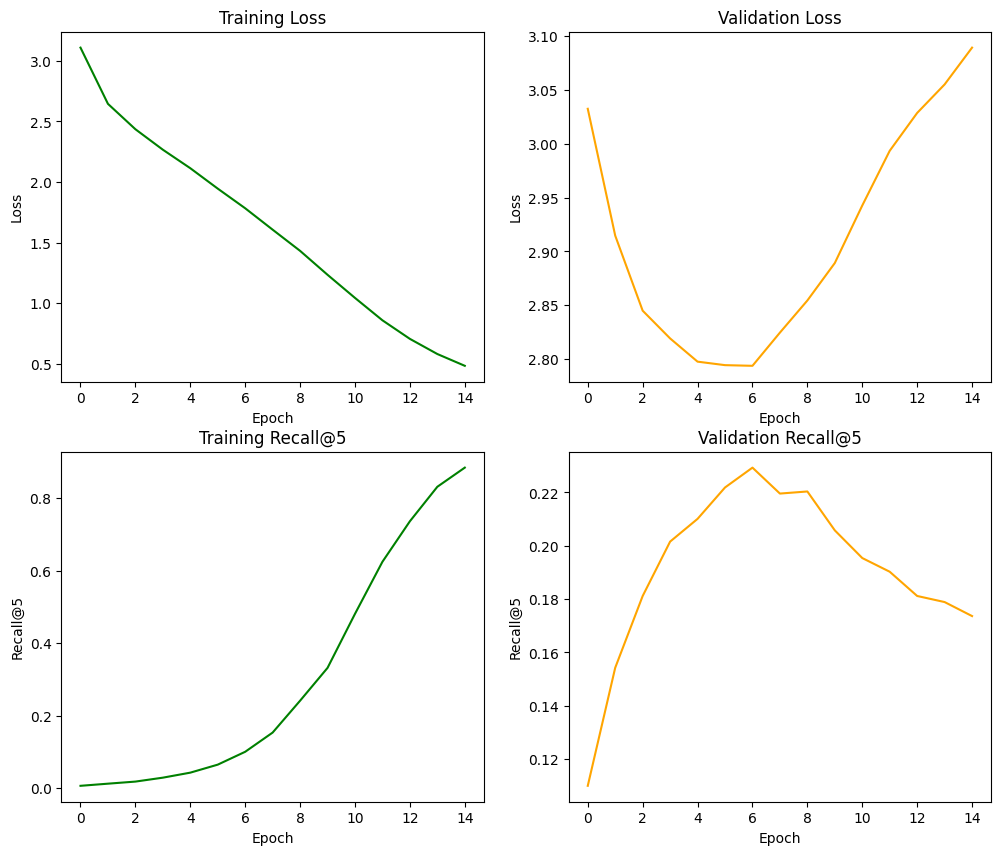

In [ ]:
# Plot for average session

# Convert GPU tensors in metric lists to standard CPU float values for plotting
train_recall_plot = [r.cpu().item() if isinstance(r, torch.Tensor) else r for r in train_recalls_at_5]
val_recall_plot = [r.cpu().item() if isinstance(r, torch.Tensor) else r for r in val_recalls_at_5]

fig, ax = plt.subplots(2, 2, figsize=(12, 10))
ax[0, 0].plot(train_losses, color='green')
ax[0, 0].set(xlabel='Epoch', ylabel='Loss')
ax[0, 0].set_title('Training Loss')

ax[0, 1].plot(val_losses, color='orange')
ax[0, 1].set(xlabel='Epoch', ylabel='Loss')
ax[0, 1].set_title('Validation Loss')

ax[1, 0].plot(train_recall_plot, color='green')
ax[1, 0].set(xlabel='Epoch', ylabel='Recall@5')
ax[1, 0].set_title('Training Recall@5')

ax[1, 1].plot(val_recall_plot, color='orange')
ax[1, 1].set(xlabel='Epoch', ylabel='Recall@5')
ax[1, 1].set_title('Validation Recall@5')

plt.show()


## Testing

In [31]:
!pip -q install gdown

!mkdir "/content/DataStorage/EEG_Classification/checkpoints"
!mkdir "/content/DataStorage/EEG_Classification/checkpoints/Exp_avg"
!mkdir "/content/DataStorage/EEG_Classification/checkpoints/Exp_non_avg"
!mkdir "/content/DataStorage/EEG_Classification/result"


In [32]:
# ==========================================
# DOWNLOAD MODEL CHECKPOINTS
# ==========================================

!pip -q install gdown

import os
import gdown

# Base directory
base_dir = "/content/DataStorage/EEG_Classification/checkpoints"

# Google Drive links and corresponding save paths
files = {
    "Exp_avg": {
        "best_model_MLP.pth":
            "https://drive.google.com/file/d/1R0ed0pSv91ILe6mmSgcbdhN8yqe9IP4P/view?usp=drive_link",

        "best_model_Conv1D.pth":
            "https://drive.google.com/file/d/1zLdpnrHsKctKjQkC-G41Qtg9srPh2_0e/view?usp=drive_link"
    },

    "Exp_non_avg": {
        "best_model_MLP_ex3.pth":
            "https://drive.google.com/file/d/10szgg22_8HTfJC7UvwfN5ZLVjiT8scDO/view?usp=drive_link",

        "best_model_Conv1D.pth":
            "https://drive.google.com/file/d/1l4ZVm3LKLt6MlbG6SKkNiqhfMVNqwJSJ/view?usp=drive_link"
    }
}

# Create folders and download files
for experiment, model_files in files.items():

    save_dir = os.path.join(base_dir, experiment)
    os.makedirs(save_dir, exist_ok=True)

    print(f"\nDownloading {experiment}...")

    for filename, url in model_files.items():

        output_path = os.path.join(save_dir, filename)

        print(f"Downloading {filename}...")

        result = gdown.download(
            url=url,
            output=output_path,
            quiet=False,
            fuzzy=True
        )

        if result is None:
            print(f"Download failed: {filename}")
        else:
            print(f"Saved to: {output_path}")

print("\nDownload process completed!")

Downloading...
From (original): https://drive.google.com/uc?id=1R0ed0pSv91ILe6mmSgcbdhN8yqe9IP4P
From (redirected): https://drive.google.com/uc?id=1R0ed0pSv91ILe6mmSgcbdhN8yqe9IP4P&confirm=t&uuid=9f58cd83-3d65-49ad-887f-71ab12acabbe
To: /content/DataStorage/EEG_Classification/checkpoints/Exp_avg/best_model_MLP.pth
100%|██████████| 83.8M/83.8M [00:02<00:00, 37.9MB/s]


Saved to: /content/DataStorage/EEG_Classification/checkpoints/Exp_avg/best_model_MLP.pth


Downloading...
From (original): https://drive.google.com/uc?id=1zLdpnrHsKctKjQkC-G41Qtg9srPh2_0e
From (redirected): https://drive.google.com/uc?id=1zLdpnrHsKctKjQkC-G41Qtg9srPh2_0e&confirm=t&uuid=9308703a-666e-4611-ba61-55f5fe381b83
To: /content/DataStorage/EEG_Classification/checkpoints/Exp_avg/best_model_Conv1D.pth
100%|██████████| 63.9M/63.9M [00:02<00:00, 30.2MB/s]


Saved to: /content/DataStorage/EEG_Classification/checkpoints/Exp_avg/best_model_Conv1D.pth



Downloading...
From (original): https://drive.google.com/uc?id=10szgg22_8HTfJC7UvwfN5ZLVjiT8scDO
From (redirected): https://drive.google.com/uc?id=10szgg22_8HTfJC7UvwfN5ZLVjiT8scDO&confirm=t&uuid=08191283-0d82-45a6-acbd-27c5d147f33e
To: /content/DataStorage/EEG_Classification/checkpoints/Exp_non_avg/best_model_MLP_ex3.pth
100%|██████████| 83.8M/83.8M [00:02<00:00, 34.1MB/s]


Saved to: /content/DataStorage/EEG_Classification/checkpoints/Exp_non_avg/best_model_MLP_ex3.pth


Downloading...
From (original): https://drive.google.com/uc?id=1l4ZVm3LKLt6MlbG6SKkNiqhfMVNqwJSJ
From (redirected): https://drive.google.com/uc?id=1l4ZVm3LKLt6MlbG6SKkNiqhfMVNqwJSJ&confirm=t&uuid=ecd7080c-3b39-436c-b3c0-d48965befe45
To: /content/DataStorage/EEG_Classification/checkpoints/Exp_non_avg/best_model_Conv1D.pth
100%|██████████| 63.9M/63.9M [00:01<00:00, 41.5MB/s]

Saved to: /content/DataStorage/EEG_Classification/checkpoints/Exp_non_avg/best_model_Conv1D.pth

Download process completed!


In [33]:
import torch
import numpy as np
import pandas as pd
import os

# ==========================================
# MODEL CHECKPOINTS
# ==========================================

model_paths = {
    "Experiment_MLP_Avg": "/content/DataStorage/EEG_Classification/checkpoints/Exp_avg/best_model_MLP.pth",
    "Experiment_Conv1D_avg": "/content/DataStorage/EEG_Classification/checkpoints/Exp_avg/best_model_Conv1D.pth",
    "Experiment_MLP_NonAvg": "/content/DataStorage/EEG_Classification/checkpoints/Exp_non_avg/best_model_MLP_ex3.pth",
    "Experiment_Conv1d_NonAvg": "/content/DataStorage/EEG_Classification/checkpoints/Exp_non_avg/best_model_Conv1D.pth"
}

In [34]:
# ==========================================
# INITIALIZE 4 MODELS
# ==========================================

input_dims_mlp = 63 * 100

models = {
    "Experiment_MLP_Avg": MLP(
        input_dims=input_dims_mlp,
        hidden1_dims=1024,
        hidden2_dims=512,
        output_dims=512
    ),

    "Experiment_Conv1D_avg": ImprovedConv1d_v2(
        input_channels=63,
        output_dims=512
    ),

    "Experiment_MLP_NonAvg": MLP(
        input_dims=input_dims_mlp,
        hidden1_dims=1024,
        hidden2_dims=512,
        output_dims=512
    ),

    "Experiment_Conv1d_NonAvg": ImprovedConv1d_v2(
        input_channels=63,
        output_dims=512
    )
}

In [35]:
# ==========================================
# LOAD BEST CHECKPOINTS
# ==========================================

for model_name, model in models.items():

    checkpoint = torch.load(
        model_paths[model_name],
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model.to(device)
    model.eval()

    print(
        f"{model_name}: "
        f"Loaded from epoch {checkpoint['epoch']}"
    )

Experiment_MLP_Avg: Loaded from epoch 3
Experiment_Conv1D_avg: Loaded from epoch 7
Experiment_MLP_NonAvg: Loaded from epoch 95
Experiment_Conv1d_NonAvg: Loaded from epoch 100


## For AVERAGE: Tesing

In [36]:
# ==========================================
# EVALUATION: AVERAGE 80 REPETITIONS
# ==========================================

@torch.no_grad()
def evaluate_model_avg80(
    model,
    test_loader,
    device,
    ks=(1, 5, 10)
):

    model = model.to(device)
    model.eval()

    eeg_embeddings_list = []
    image_embeddings_list = []
    concept_ids_list = []

    # 1. Inference
    for eeg, target, concept_id in test_loader:

        eeg = eeg.to(device)

        output = model(eeg)

        if isinstance(output, (tuple, list)):
            output = output[0]

        assert output.ndim == 2 and output.shape[1] == 512, (
            f"Expected output shape (batch, 512), "
            f"but got {tuple(output.shape)}"
        )

        eeg_embeddings_list.append(output)

        image_embeddings_list.append(target.to(device))

        concept_ids_list.append(concept_id.to(device))

    # 2. Concatenate all batches
    eeg_embeddings = torch.cat(
        eeg_embeddings_list, dim=0
    )

    image_embeddings = torch.cat(
        image_embeddings_list, dim=0
    )

    concept_ids = torch.cat(
        concept_ids_list, dim=0
    )

    # 3. Calculate Recall@K
    results = calculate_recall_at_k(
        eeg_embeddings=eeg_embeddings,
        image_embeddings=image_embeddings,
        eeg_concept_ids=concept_ids,
        image_concept_ids=concept_ids,
        ks=ks
    )

    return results

In [37]:
# ==========================================
# EVALUATE ALL 4 MODELS
# AVERAGE 80 REPETITIONS
# ==========================================

results_avg80 = {}

for model_name, model in models.items():

    print(f"\nEvaluating {model_name}...")

    results = evaluate_model_avg80(
        model=model,
        test_loader=test_loader_avg,
        device=device,
        ks=(1, 5, 10)
    )

    results_avg80[model_name] = results

    print(f"\n{model_name} - Average 80 repetitions")

    for metric, value in results.items():
        print(f"{metric}: {value:.4f}")


Evaluating Experiment_MLP_Avg...

Experiment_MLP_Avg - Average 80 repetitions
Recall@1: 0.1500
Recall@5: 0.3800
Recall@10: 0.5450

Evaluating Experiment_Conv1D_avg...

Experiment_Conv1D_avg - Average 80 repetitions
Recall@1: 0.1500
Recall@5: 0.4100
Recall@10: 0.5650

Evaluating Experiment_MLP_NonAvg...

Experiment_MLP_NonAvg - Average 80 repetitions
Recall@1: 0.0700
Recall@5: 0.2550
Recall@10: 0.4200

Evaluating Experiment_Conv1d_NonAvg...

Experiment_Conv1d_NonAvg - Average 80 repetitions
Recall@1: 0.0550
Recall@5: 0.2150
Recall@10: 0.4000


In [ ]:
# ==========================================
# SUMMARY RESULTS
# ==========================================

df_results_avg80 = pd.DataFrame.from_dict(
    results_avg80,
    orient="index"
)

df_results_avg80.index.name = "Model"

print(df_results_avg80.round(4))

df_results_avg80.to_csv(
    "test_results_average_80_repetitions.csv"
)

                          Recall@1  Recall@5  Recall@10
Model                                                  
Experiment_MLP_Avg           0.085     0.275      0.420
Experiment_Conv1D_avg        0.060     0.160      0.245
Experiment_MLP_NonAvg        0.025     0.105      0.195
Experiment_Conv1d_NonAvg     0.040     0.215      0.385


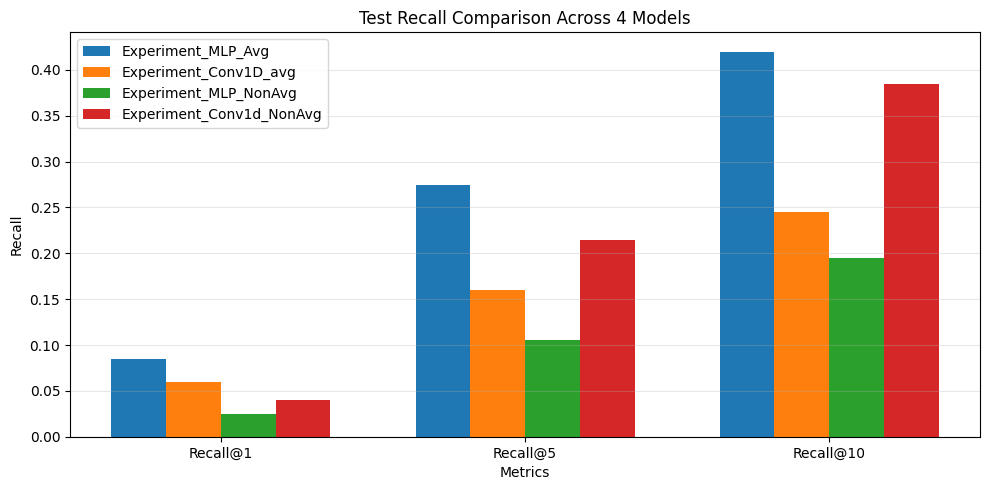

In [ ]:
import matplotlib.pyplot as plt

# ==========================================
# PLOT TEST RECALL COMPARISON
# ==========================================

metrics = ["Recall@1", "Recall@5", "Recall@10"]

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(metrics))
width = 0.18

# Fix: Loop over results_avg80.keys() instead of results.keys()
for i, model_name in enumerate(results_avg80.keys()):

    values = [
        results_avg80[model_name][metric]
        for metric in metrics
    ]

    ax.bar(
        x + i * width,
        values,
        width,
        label=model_name
    )

ax.set_xlabel("Metrics")
ax.set_ylabel("Recall")
ax.set_title("Test Recall Comparison Across 4 Models")

ax.set_xticks(
    x + width * (len(results_avg80) - 1) / 2
)

ax.set_xticklabels(metrics)

ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()